# 0. 环境配置

本格会在 **Notebook 当前目录** 创建 `.venv` 并安装依赖。完成后必须在 Jupyter 右上角切换到新出现的 **Python (Nanjing Car Rental)** 内核，然后**重启内核**并从下一格继续运行。Jupyter 不能在当前运行中的内核里自动切换到新环境。

In [1]:
%%bash
set -euo pipefail
python3 -m venv .venv
./.venv/bin/python -m pip install --upgrade pip
./.venv/bin/python -m pip install --only-binary=:all: --prefer-binary -r requirements.txt
./.venv/bin/python -m ipykernel install --user --name nanjing-car-rental --display-name 'Python (Nanjing Car Rental)'
echo '环境已创建。请切换 Jupyter 内核至 Python (Nanjing Car Rental)，然后重启内核。'


Installed kernelspec nanjing-car-rental in /Users/blue44/Library/Jupyter/kernels/nanjing-car-rental
环境已创建。请切换 Jupyter 内核至 Python (Nanjing Car Rental)，然后重启内核。


# 0.1 设置高德与 CARTO Key

在实际工程中建议`export AMAP_WEB_SERVICE_KEY='你的Key'` 和 `export CARTO_API_KEY='你的Carto Basemaps API Key'`。为了简化，直接硬编码了高德和CARTO地图key，在实际工程中有暴露风险。

In [1]:
import os
os.environ['AMAP_WEB_SERVICE_KEY'] = '86575734d7ee6c7f7854d0c3d1b029f3'
os.environ['CARTO_API_KEY'] = 'cb1_4e3u_1_caa64ebbab8e407c53377323'
if os.getenv('AMAP_WEB_SERVICE_KEY') and os.getenv('CARTO_API_KEY'):
    print('AMAP_WEB_SERVICE_KEY 和 CARTO_API_KEY 已设置。')
else:
    print('No Avaliable API Keys')


AMAP_WEB_SERVICE_KEY 和 CARTO_API_KEY 已设置。


# 南京租车 POI 空间分析

> **坐标系重点：高德 `location` 按 GCJ-02 处理；先反算 WGS84，再投影为 EPSG:32650（UTM 50N）。** Folium 地图采用 WGS84，米制距离和 3km 密度采用 UTM 坐标。

按顺序运行。输出位于 `data/` 和 `analysis/`。

## 安装


>先检查运行内核是否是刚创建的新内核，如果不是，需要选择新内核并重启内核

In [2]:
import sys
print('当前内核：', sys.executable)



当前内核： /Users/blue44/Desktop/空间分析/2026learngit/孙涵-2026.10.08-第一次作业/carent/.venv/bin/python


In [3]:
from __future__ import annotations
import json, math, os, time
from pathlib import Path
import folium, matplotlib.pyplot as plt, numpy as np, pandas as pd, requests
from folium.plugins import HeatMap, MarkerCluster
from pyproj import Transformer
from sklearn.cluster import DBSCAN

BASE=Path.cwd(); DATA=BASE/'data'; OUT=BASE/'analysis'; DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
KEY=os.getenv('AMAP_WEB_SERVICE_KEY',''); CARTO_API_KEY=os.getenv('CARTO_API_KEY',''); API='https://restapi.amap.com/v3/place/text'; CITY='320100'
# CARTO Raster Voyager 的官方格式：Key 通过 ?key= 参数传递。
CARTO_TILE_URL=os.getenv('CARTO_TILE_URL','https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png?key={api_key}')
# 高德 10021 是账号共享的地点搜索 QPS 限流；不要并行运行下载单元格。
REQUEST_INTERVAL_SECONDS = 3.0
if not KEY: print('请先设置 AMAP_WEB_SERVICE_KEY 并重启内核。')

def amap(keyword, types=''):
    if not KEY: raise ValueError('缺少 AMAP_WEB_SERVICE_KEY。')
    result=[]
    for page in range(1,9):
        p={'key':KEY,'keywords':keyword,'city':CITY,'citylimit':'true','offset':25,'page':page,'extensions':'base','output':'JSON'}
        if types: p['types']=types
        # 单线程串行调用；遇到账号级 QPS 限流时逐步退避重试。
        for attempt in range(10):
            r=requests.get(API,params=p,timeout=25); r.raise_for_status(); body=r.json()
            if body.get('status')=='1': break
            if str(body.get('infocode'))=='10021' and attempt < 9:
                wait=min(60, 5*(attempt+1)); print(f'高德账号级 QPS 限流，{wait} 秒后重试（第 {attempt+1}/10 次）…'); time.sleep(wait); continue
            raise RuntimeError(f"高德 API：{body.get('info')} ({body.get('infocode')})。当前账号地点搜索 QPS 持续超限，请停止其他请求或在高德控制台提升 QPS。")
        pois=body.get('pois',[]); result.extend(pois)
        if len(pois)<25: break
        time.sleep(REQUEST_INTERVAL_SECONDS)
    return result

def tidy(items):
    rows=[]
    for p in items:
        try: lon,lat=map(float,p['location'].split(','))
        except (KeyError,ValueError): continue
        rows.append({'id':p.get('id',''),'name':p.get('name',''),'address':p.get('address',''),'adname':p.get('adname',''),'longitude':lon,'latitude':lat})
    return pd.DataFrame(rows).drop_duplicates('id')


In [4]:
# 下载/读取租车 POI
poi_file=DATA/'nanjing_car_rental_pois.csv'
if poi_file.exists(): rentals_raw=pd.read_csv(poi_file)
else:
    words=['租车','汽车租赁','神州租车','一嗨租车','悟空租车','联动云租车']
    rentals_raw=tidy([p for w in words for p in amap(w,'010900')]); rentals_raw.to_csv(poi_file,index=False,encoding='utf-8-sig')
print('租车 POI：',len(rentals_raw)); rentals_raw.head()

租车 POI： 258


,id,name,address,adname,longitude,latitude
0,B0G0GRJZNC,一嗨租车(南京南站南广场店),玉兰路98号南京南站南广场P7停车场B2层,江宁区,118.800343,31.966813
1,B0FFFZYZ85,神州租车(禄口机场T2服务点),纬六路南京禄口国际机场T2航站楼2号停车场2楼平台,江宁区,118.875408,31.731305
2,B0FFFZYYVR,一嗨租车(禄口国际机场T2店),禄口国际机场P2停车场B2层K区,江宁区,118.876021,31.731950
3,B0G39SN8FG,一嗨租车(南京火车站店),南京火车站北广场西停车场负二层C区,鼓楼区,118.796694,32.089647
4,B0KDFX2GKW,马达租车(南京南站店),新坤停车场软件大道二手车交易市场,雨花台区,118.795879,31.979093


## 投影转换与自动核验

南京原始高德坐标应落在 118–120°E、31–33°N。转换后的 UTM Easting/Northing 约为 50–80 万米 / 330–370 万米；断言失败时不可继续分析。

In [5]:
PI=math.pi; A=6378245.; EE=.00669342162296594323
def outside(x,y): return not(72.004<=x<=137.8347 and .8293<=y<=55.8271)
def tlat(x,y): return -100+2*x+3*y+.2*y*y+.1*x*y+.2*math.sqrt(abs(x))+(20*math.sin(6*x*PI)+20*math.sin(2*x*PI))*2/3+(20*math.sin(y*PI)+40*math.sin(y*PI/3))*2/3+(160*math.sin(y*PI/12)+320*math.sin(y*PI/30))*2/3
def tlon(x,y): return 300+x+2*y+.1*x*x+.1*x*y+.1*math.sqrt(abs(x))+(20*math.sin(6*x*PI)+20*math.sin(2*x*PI))*2/3+(20*math.sin(x*PI)+40*math.sin(x*PI/3))*2/3+(150*math.sin(x*PI/12)+300*math.sin(x*PI/30))*2/3
def wgs2gcj(x,y):
    if outside(x,y): return x,y
    a,b=tlat(x-105,y-35),tlon(x-105,y-35); r=y*PI/180; m=1-EE*math.sin(r)**2; s=math.sqrt(m)
    return x+b*180/(A/s*math.cos(r)*PI),y+a*180/(A*(1-EE)/(m*s)*PI)
def gcj2wgs(x,y):
    ox,oy=x,y
    for _ in range(2):
        gx,gy=wgs2gcj(x,y); x,y=x+ox-gx,y+oy-gy
    return x,y
# 南京（118–119°E）位于 UTM 50N，中央经线为 117°E。
utm=Transformer.from_crs('EPSG:4326','EPSG:32650',always_xy=True)
def project(df):
    z=df.copy(); z[['longitude_gcj02','latitude_gcj02']]=z[['longitude','latitude']].astype(float)
    w=z.apply(lambda r: gcj2wgs(r.longitude_gcj02,r.latitude_gcj02),axis=1,result_type='expand'); z[['longitude_wgs84','latitude_wgs84']]=w
    z['x_utm_m'],z['y_utm_m']=utm.transform(z.longitude_wgs84.to_numpy(),z.latitude_wgs84.to_numpy()); return z
rentals=project(rentals_raw)
assert rentals.longitude_gcj02.between(118,120).all() and rentals.latitude_gcj02.between(31,33).all(),'原始坐标不在南京范围'
assert rentals.x_utm_m.between(500000,800000).all() and rentals.y_utm_m.between(3300000,3700000).all(),'UTM 投影异常'
display(rentals[['name','longitude_gcj02','latitude_gcj02','longitude_wgs84','latitude_wgs84','x_utm_m','y_utm_m']].head())

,name,longitude_gcj02,latitude_gcj02,longitude_wgs84,latitude_wgs84,x_utm_m,y_utm_m
0,一嗨租车(南京南站南广场店),118.800343,31.966813,118.795165,31.968865,669632.483986,3.538392e+06
1,神州租车(禄口机场T2服务点),118.875408,31.731305,118.870394,31.733440,677192.121393,3.512412e+06
2,一嗨租车(禄口国际机场T2店),118.876021,31.731950,118.871008,31.734086,677249.043232,3.512484e+06
3,一嗨租车(南京火车站店),118.796694,32.089647,118.791499,32.091722,669060.043834,3.552007e+06
4,马达租车(南京南站店),118.795879,31.979093,118.790693,31.981142,669187.282530,3.539746e+06


In [ ]:
# 高铁/铁路站、地铁站、禄口机场，以及 UTM 米制距离分析
names=['南京南站','南京站','江宁站','溧水站','仙林站']
h0=tidy([p for n in names for p in amap(n)]); hsr=pd.concat([h0[h0.name.eq(n)].head(1) for n in names],ignore_index=True).dropna(how='all')
metro=tidy(amap('','150500')); metro=metro if not metro.empty else tidy(amap('地铁站'))
# 禄口机场：优先使用主 POI 的精确名称，避免误选航站楼、停车场等子 POI。
airport_candidates=tidy(amap('南京禄口国际机场'))
airport=airport_candidates[airport_candidates.name.eq('南京禄口国际机场')].head(1)
if airport.empty: airport=airport_candidates.head(1)
if airport.empty: raise RuntimeError('未查询到南京禄口国际机场 POI。')
hsr,metro,airport=project(hsr),project(metro),project(airport)
def nearest(a,b):
    d=np.hypot(a.x_utm_m.to_numpy()[:,None]-b.x_utm_m.to_numpy()[None,:],a.y_utm_m.to_numpy()[:,None]-b.y_utm_m.to_numpy()[None,:]); i=d.argmin(1); return d[np.arange(len(a)),i],i
d,i=nearest(rentals,hsr); rentals['nearest_hsr_km']=d/1000; rentals['nearest_hsr_name']=hsr.iloc[i]['name'].to_numpy()
d,i=nearest(rentals,metro); rentals['nearest_metro_km']=d/1000; rentals['nearest_metro_name']=metro.iloc[i]['name'].to_numpy()
d,i=nearest(rentals,airport); rentals['nearest_lukou_airport_km']=d/1000; rentals['nearest_lukou_airport_name']=airport.iloc[i]['name'].to_numpy()
# 高铁/铁路站与禄口机场合并为综合交通枢纽，供统计图使用。
transport_hubs=pd.concat([hsr,airport],ignore_index=True)
d,i=nearest(rentals,transport_hubs); rentals['nearest_hsr_rail_airport_km']=d/1000; rentals['nearest_hsr_rail_airport_name']=transport_hubs.iloc[i]['name'].to_numpy()
airport_5km=rentals[rentals.nearest_lukou_airport_km<=5].copy()
print(f'示例:禄口机场 5 km 直线范围内租车点：{len(airport_5km)} 个；最近点距离：{rentals.nearest_lukou_airport_km.min():.2f} km')
display(airport_5km[['name','address','nearest_lukou_airport_km']].sort_values('nearest_lukou_airport_km'))
d=np.hypot(rentals.x_utm_m.to_numpy()[:,None]-rentals.x_utm_m.to_numpy()[None,:],rentals.y_utm_m.to_numpy()[:,None]-rentals.y_utm_m.to_numpy()[None,:]); np.fill_diagonal(d,np.inf)
rentals['nearest_rental_km']=d.min(1)/1000 if len(rentals)>1 else np.nan; rentals['other_rentals_within_3km']=(d<=3000).sum(1)

禄口机场 5 km 直线范围内租车点：9 个；最近点距离：0.40 km


,name,address,nearest_lukou_airport_km
235,EVCARD南京租车,禄口国际机场T2航站楼(P2露天停车场),0.398320
1,神州租车(禄口机场T2服务点),纬六路南京禄口国际机场T2航站楼2号停车场2楼平台,0.402728
2,一嗨租车(禄口国际机场T2店),禄口国际机场P2停车场B2层K区,0.460672
110,侣行汽车租赁,翔鹰二路与经十路交叉口西北100米,1.435250
174,鑫泰鸿租车,禄口街道11号,2.028798
11,马达租车(南京禄口机场店),南京禄航停车场,2.197174
257,江苏弛扬汽车租赁有限公司(禄口店),官庄路2号,3.176255
179,捷凯租车,香江华庭111号,4.119966
201,神州租车(麗枫酒店自助点),金航路55号,4.491729


In [7]:
# Folium/Leaflet 接收 WGS84 经纬度，并自动投影到 CARTO Raster 底图使用的 Web Mercator。
# 因此此处必须使用 longitude_wgs84 / latitude_wgs84，不能使用原始 GCJ-02 经纬度。
tile_url=CARTO_TILE_URL.replace('{api_key}', CARTO_API_KEY)
if '{api_key}' in CARTO_TILE_URL and not CARTO_API_KEY: raise ValueError('CARTO_TILE_URL 需要 CARTO_API_KEY，请先运行 0.1 设置 Key 单元。')
m=folium.Map([rentals.latitude_wgs84.mean(),rentals.longitude_wgs84.mean()],zoom_start=10,tiles=None)
folium.TileLayer(tiles=tile_url, attr='© OpenStreetMap contributors © CARTO', name='CARTO Positron', overlay=False, control=True).add_to(m)
HeatMap(rentals[['latitude_wgs84','longitude_wgs84']].values.tolist(),radius=18,blur=14).add_to(m); c=MarkerCluster(name='租车行').add_to(m)
for r in rentals.itertuples(): folium.CircleMarker([r.latitude_wgs84,r.longitude_wgs84],radius=5,color='#dc2626',fill=True,popup=f'{r.name}<br>高铁 {r.nearest_hsr_km:.1f} km；地铁 {r.nearest_metro_km:.1f} km').add_to(c)
for frame,color in [(hsr,'blue'),(metro,'green')]:
    for r in frame.itertuples(): folium.Marker([r.latitude_wgs84,r.longitude_wgs84],tooltip=r.name,icon=folium.Icon(color=color,icon='train',prefix='fa')).add_to(m)
for r in airport.itertuples(): folium.Marker([r.latitude_wgs84,r.longitude_wgs84],tooltip='南京禄口国际机场',icon=folium.Icon(color='purple',icon='plane',prefix='fa')).add_to(m)
m.save(OUT/'nanjing_car_rental_map.html'); m

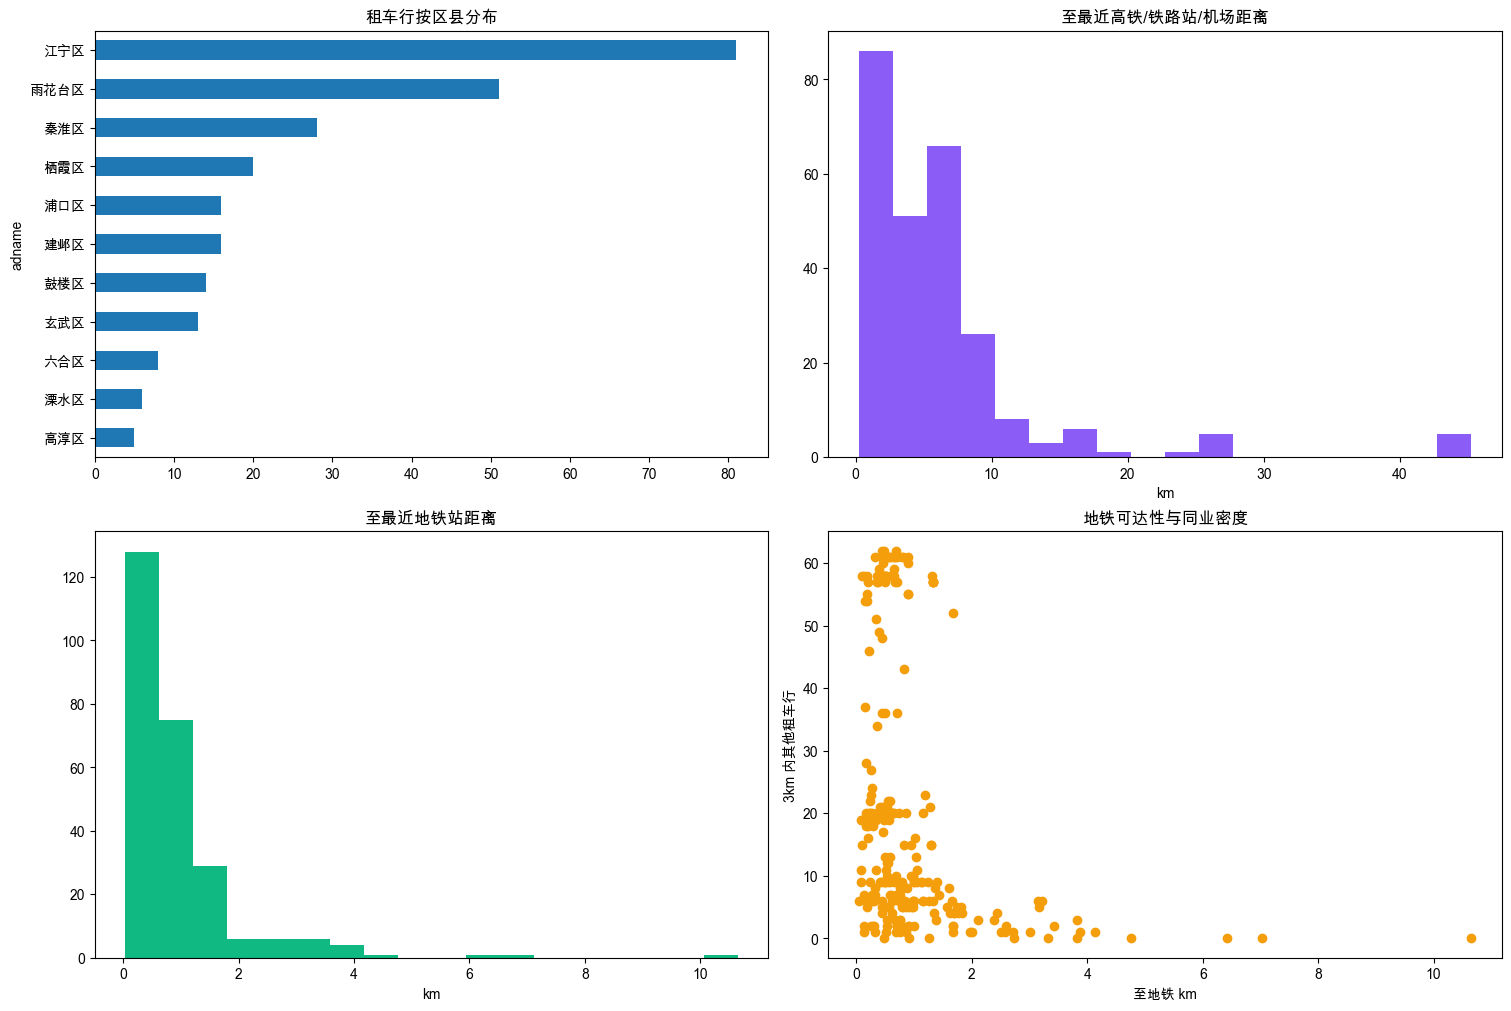

{'poi_count': 258,
 'median_hsr_km': 5.25,
 'median_metro_km': 0.648,
 'coordinate_system': 'GCJ-02 -> WGS84 -> EPSG:32650 (UTM 50N)'}

In [8]:
plt.rcParams['font.sans-serif']=['PingFang SC','Microsoft YaHei','SimHei','Arial Unicode MS','DejaVu Sans']; plt.rcParams['axes.unicode_minus']=False
fig,ax=plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
rentals.adname.fillna('未标注区县').value_counts().sort_values().plot.barh(ax=ax[0,0],title='租车行按区县分布')
ax[0,1].hist(rentals.nearest_hsr_rail_airport_km,bins=18,color='#8b5cf6'); ax[0,1].set(title='至最近高铁/铁路站/机场距离',xlabel='km')
ax[1,0].hist(rentals.nearest_metro_km,bins=18,color='#10b981'); ax[1,0].set(title='至最近地铁站距离',xlabel='km')
ax[1,1].scatter(rentals.nearest_metro_km,rentals.other_rentals_within_3km,color='#f59e0b'); ax[1,1].set(title='地铁可达性与同业密度',xlabel='至地铁 km',ylabel='3km 内其他租车行')
fig.savefig(OUT/'nanjing_car_rental_statistics.png',dpi=180); plt.show()
rentals.to_csv(OUT/'rental_poi_enriched_projected.csv',index=False,encoding='utf-8-sig')
summary={'poi_count':len(rentals),'median_hsr_km':round(float(rentals.nearest_hsr_km.median()),3),'median_metro_km':round(float(rentals.nearest_metro_km.median()),3),'coordinate_system':'GCJ-02 -> WGS84 -> EPSG:32650 (UTM 50N)'}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8'); summary

## 空间聚类分析（DBSCAN）

DBSCAN 基于 UTM 50N 米制坐标识别租车点的高密度簇，不需要预先设定簇数。这里将 2 km 内至少有 3 个点的区域识别为一个簇，未被归入任意簇的点标为“离群点”。

DBSCAN 参数：eps=2.0 km，min_samples=3
识别到 12 个空间簇；离群点 42 个。


,spatial_cluster,poi_count,center_longitude_wgs84,center_latitude_wgs84,median_nearest_metro_km
0,0,146,118.793667,31.977556,0.498875
1,2,21,118.809993,32.105389,0.792883
2,4,9,118.842634,32.025128,0.877863
3,1,7,118.878451,31.735372,0.436271
4,5,7,118.717094,32.139785,0.611474
5,7,6,118.870899,31.982959,2.399402
6,8,4,118.893828,31.920678,0.710890
7,9,4,118.894351,32.044481,1.486728
8,3,3,118.972731,32.118410,0.531422
9,6,3,118.889177,31.331944,2.111817


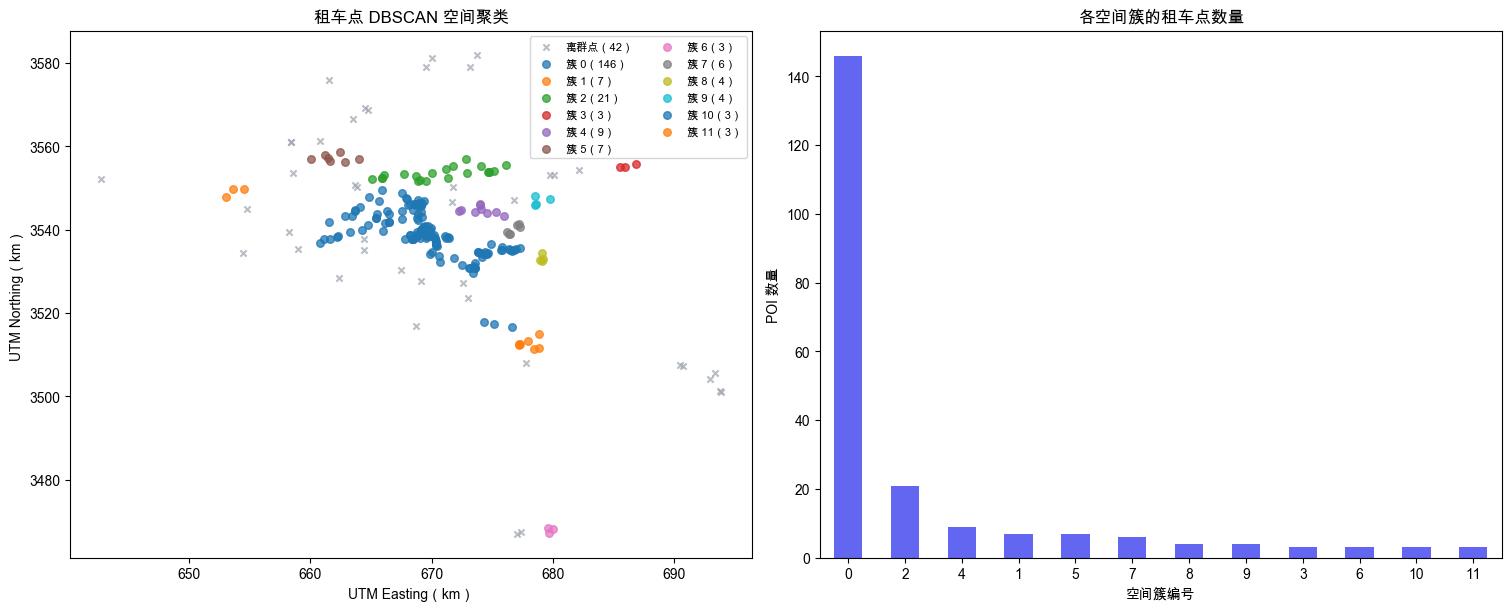

聚类图：/Users/blue44/Desktop/空间分析/2026learngit/孙涵-2026.10.08-第一次作业/carent/analysis/nanjing_car_rental_dbscan_clusters.png
聚类底图：/Users/blue44/Desktop/空间分析/2026learngit/孙涵-2026.10.08-第一次作业/carent/analysis/nanjing_car_rental_dbscan_cluster_map.html


In [9]:
# DBSCAN 的 eps 单位为米，因为输入为 EPSG:32650 的 x_utm_m / y_utm_m。
DBSCAN_EPS_METERS = 2000
DBSCAN_MIN_SAMPLES = 3
coordinates = rentals[['x_utm_m', 'y_utm_m']].to_numpy()
rentals['spatial_cluster'] = DBSCAN(eps=DBSCAN_EPS_METERS, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(coordinates)
cluster_sizes = rentals[rentals.spatial_cluster >= 0].groupby('spatial_cluster').size().sort_values(ascending=False)
cluster_summary = (rentals[rentals.spatial_cluster >= 0].groupby('spatial_cluster')
    .agg(poi_count=('id', 'size'), center_longitude_wgs84=('longitude_wgs84', 'mean'), center_latitude_wgs84=('latitude_wgs84', 'mean'), median_nearest_metro_km=('nearest_metro_km', 'median'))
    .sort_values('poi_count', ascending=False).reset_index())
noise_count = int((rentals.spatial_cluster == -1).sum())
print(f'DBSCAN 参数：eps={DBSCAN_EPS_METERS / 1000:.1f} km，min_samples={DBSCAN_MIN_SAMPLES}')
print(f'识别到 {len(cluster_sizes)} 个空间簇；离群点 {noise_count} 个。')
display(cluster_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
labels = sorted(rentals.spatial_cluster.unique())
for label in labels:
    subset = rentals[rentals.spatial_cluster == label]
    if label == -1:
        axes[0].scatter(subset.x_utm_m / 1000, subset.y_utm_m / 1000, s=20, c='#9ca3af', marker='x', alpha=.7, label=f'离群点（{len(subset)}）')
    else:
        axes[0].scatter(subset.x_utm_m / 1000, subset.y_utm_m / 1000, s=30, alpha=.75, label=f'簇 {label}（{len(subset)}）')
axes[0].set(title='租车点 DBSCAN 空间聚类', xlabel='UTM Easting（km）', ylabel='UTM Northing（km）')
axes[0].legend(loc='best', fontsize=8, ncol=2)
cluster_sizes.plot.bar(ax=axes[1], color='#6366f1')
axes[1].set(title='各空间簇的租车点数量', xlabel='空间簇编号', ylabel='POI 数量')
axes[1].tick_params(axis='x', rotation=0)
cluster_chart_path = OUT / 'nanjing_car_rental_dbscan_clusters.png'
fig.savefig(cluster_chart_path, dpi=180, bbox_inches='tight')
plt.show()
cluster_summary.to_csv(OUT / 'nanjing_car_rental_dbscan_cluster_summary.csv', index=False, encoding='utf-8-sig')
rentals.to_csv(OUT / 'rental_poi_enriched_projected.csv', index=False, encoding='utf-8-sig')
print(f'聚类图：{cluster_chart_path}')

# 将 DBSCAN 结果叠加至 CARTO 底图：同一空间簇为同一颜色，灰色叉号为离群点。
cluster_palette = ['#2563eb', '#dc2626', '#16a34a', '#9333ea', '#ea580c', '#0891b2', '#be123c', '#4d7c0f']
def cluster_color(label):
    return '#6b7280' if label == -1 else cluster_palette[int(label) % len(cluster_palette)]

cluster_tile_url = CARTO_TILE_URL.replace('{api_key}', CARTO_API_KEY)
cluster_map = folium.Map([rentals.latitude_wgs84.mean(), rentals.longitude_wgs84.mean()], zoom_start=10, tiles=None)
folium.TileLayer(tiles=cluster_tile_url, attr='© OpenStreetMap contributors © CARTO', name='CARTO Voyager', overlay=False).add_to(cluster_map)
for row in rentals.itertuples():
    label_text = '离群点' if row.spatial_cluster == -1 else f'空间簇 {row.spatial_cluster}'
    folium.CircleMarker([row.latitude_wgs84, row.longitude_wgs84], radius=5, color=cluster_color(row.spatial_cluster), fill=True, fill_opacity=.82, popup=f'<b>{row.name}</b><br>{label_text}<br>最近地铁：{row.nearest_metro_km:.1f} km').add_to(cluster_map)
for frame, color, label in [(hsr, 'blue', '高铁/铁路站'), (metro, 'green', '地铁站'), (airport, 'purple', '禄口机场')]:
    for row in frame.itertuples():
        icon = 'plane' if label == '禄口机场' else 'train'
        folium.Marker([row.latitude_wgs84, row.longitude_wgs84], tooltip=label, icon=folium.Icon(color=color, icon=icon, prefix='fa')).add_to(cluster_map)
cluster_map_path = OUT / 'nanjing_car_rental_dbscan_cluster_map.html'
cluster_map.save(cluster_map_path)
print(f'聚类底图：{cluster_map_path}')
cluster_map
